# Notebook 10: CNN Without MFCC — A Log-Mel Spectrogram Ablation

Notebook 08 trained a 1D convolutional network on full per-frame MFCC sequences and found that reintroducing temporal order (discarded by Notebook 06/07's mean/std summary features) produced a large accuracy gain. That result leaves a further question open: how much of the MFCC computation does the convolutional network actually need? MFCCs are built by passing the power spectrum through a mel-scaled filterbank, compressing the result with a logarithm, and finally applying a discrete cosine transform (DCT) that decorrelates the filterbank outputs into a small set of near-independent coefficients. The DCT step exists primarily to suit classifiers — Gaussian mixture models in particular — that perform poorly on correlated input features; a convolutional network, whose filters learn arbitrary weighted combinations across the feature axis, has no equivalent requirement.

This stage isolates that question directly. Every parameter of the Notebook 08 pipeline — 25 ms frames, 10 ms hop, Hamming window, a sequence length of 350 frames, and the exact convolutional architecture and cross-validation protocol — is held fixed. The only change is the front-end representation: the DCT step of the MFCC recipe is skipped, and the network is instead trained directly on the log-mel spectrogram (40 mel bands, log-power-compressed, no cepstral decorrelation). If accuracy is comparable to or better than Notebook 08's MFCC-based result, the DCT step is not necessary for this architecture; if accuracy drops substantially, the decorrelation was contributing information the network could not otherwise recover from the raw filterbank output.

## Illustration: log-mel spectrogram vs. MFCCs, same utterance

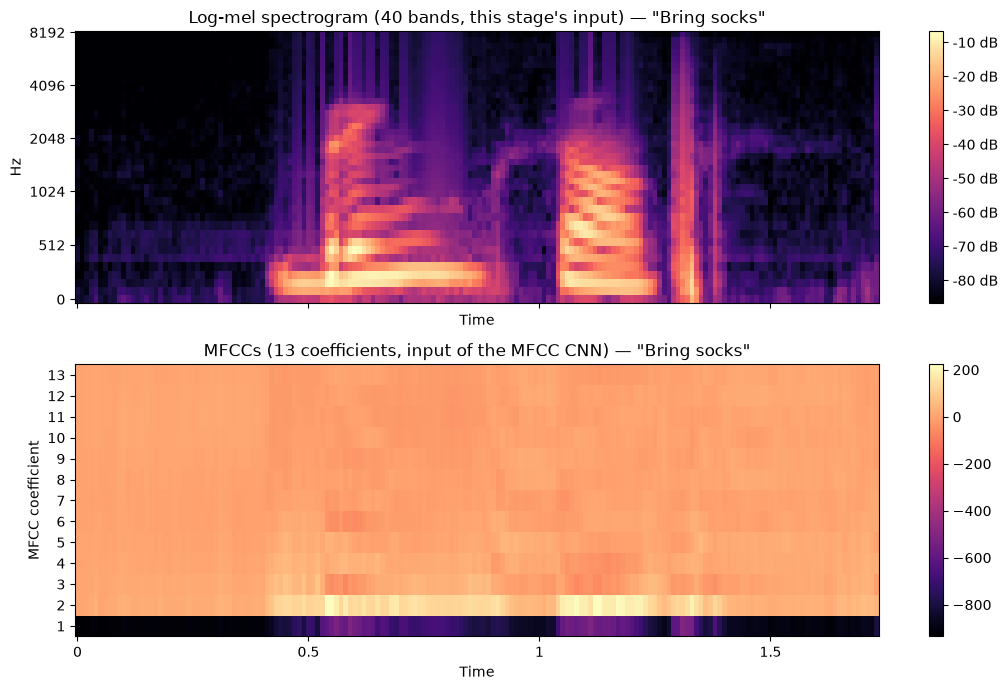

In [1]:
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt

DATA_ROOT = "../data/fluent_speech_commands_dataset"
RESULTS_ROOT = "../results"
WAV_PATH = f"{DATA_ROOT}/wavs/speakers/2BqVo8kVB2Skwgyb/ac4fca80-447a-11e9-a9a5-5dbec3b8816a.wav"
TRANSCRIPT = "Bring socks"
FRAME_LEN, HOP_LEN = 400, 160  # 25 ms / 10 ms at 16 kHz, matching Notebooks 01-08
N_MELS, N_MFCC = 40, 13

y, sr = librosa.load(WAV_PATH, sr=None)

mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=N_MELS, n_fft=FRAME_LEN,
                                      hop_length=HOP_LEN, win_length=FRAME_LEN,
                                      window="hamming", center=False)
log_mel = librosa.power_to_db(mel)

mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC, n_fft=FRAME_LEN,
                             hop_length=HOP_LEN, win_length=FRAME_LEN,
                             window="hamming", center=False)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
img0 = librosa.display.specshow(log_mel, sr=sr, hop_length=HOP_LEN, x_axis="time", y_axis="mel",
                                 fmax=sr / 2, ax=axes[0], cmap="magma")
axes[0].set_title(f'Log-mel spectrogram (40 bands, this stage\'s input) — "{TRANSCRIPT}"')
fig.colorbar(img0, ax=axes[0], format="%+.0f dB")

img1 = librosa.display.specshow(mfcc, sr=sr, hop_length=HOP_LEN, x_axis="time", ax=axes[1], cmap="magma")
axes[1].set_ylabel("MFCC coefficient")
axes[1].set_yticks(range(N_MFCC))
axes[1].set_yticklabels(range(1, N_MFCC + 1))
axes[1].set_title(f'MFCCs (13 coefficients, input of the MFCC CNN) — "{TRANSCRIPT}"')
fig.colorbar(img1, ax=axes[1])
fig.tight_layout()
plt.show()

## Reading the two representations

Both panels are derived from the same mel-filterbank output; the top panel stops after the log step, and the bottom panel additionally applies the DCT. The log-mel spectrogram (top) visually resembles a compressed, frequency-warped version of an ordinary spectrogram: energy is smoothly spread across neighbouring mel bands, since adjacent triangular filters overlap and respond similarly to the same underlying formant. The MFCC panel (bottom) looks qualitatively different — coefficient 1 dominates the colour scale because it is tied to overall frame log-energy rather than spectral shape (the same pattern noted in Notebook 07), while coefficients 2–13 vary in a way that does not visibly track formant bands, because the DCT has redistributed the mel-band energy into a decorrelated basis. This is the concrete visual counterpart of the algebraic claim above: the log-mel representation retains local, correlated structure across the frequency axis, while MFCCs deliberately remove it.

## Data preparation

Log-mel spectrogram sequences were extracted for all 30,043 utterances by `src/features/sequence_logmel.py`, using the identical 25 ms frame length, 10 ms hop, and Hamming window as every other stage, with 40 mel bands and log-power compression (`librosa.power_to_db`), and no DCT. Each utterance's (40, T) matrix is transposed to time-major (T, 40) and padded or truncated to 350 time steps — the same fixed length used for Notebook 08's MFCC sequences, so the two inputs differ only in the per-frame feature and not in temporal resolution or coverage. 40 mel bands (rather than the 128 `librosa.feature.mfcc` uses internally before its own DCT truncation) is the standard log-mel filterbank size reported in the ASR literature, and was chosen here partly because it keeps the cached array (~1.7 GB uncompressed) tractable in the memory of a typical laptop — the same kind of memory-driven scoping decision made for Notebook 11's PCA-reduced wav2vec2 sequences.

In [2]:
data = np.load(f"{DATA_ROOT}/logmel_sequences.npz", allow_pickle=True)
X, split, intent = data["X"], data["split"], data["intent"]
print(f"X shape: {X.shape}")
print(f"Splits: {pd.Series(split).value_counts().to_dict()}")
print(f"Classes: {len(set(intent))}")

X shape: (30043, 350, 40)
Splits: {'train': 23132, 'test': 3793, 'valid': 3118}
Classes: 31


## Model architecture and cross-validation protocol

The network is identical to Notebook 08's: three 1D convolutional blocks (64, 128, and 128 filters, kernel sizes 5, 5, and 3, with batch normalization and max pooling after the first two), global average pooling across time, a 128-unit dense layer with dropout, and a softmax output layer — only the input shape changes, from (350, 13) to (350, 40). Notebook 08 established that the corpus's fixed validation/test splits (10 speakers each) give unreliable accuracy estimates for this class of model, so evaluation here goes directly to the same 5-fold speaker-grouped cross-validation (`GroupKFold` on speaker ID, each fold's training speakers further split 90/10 for early-stopping validation) used from Notebook 08 onward, rather than re-deriving that result. Training and evaluation are run by `src/experiments/cnn_logmel_cv.py`, out-of-notebook, since a full 5-fold run takes on the order of tens of minutes.

 fold  held_out_acc  n_train  n_val  n_held_out
    1      0.760613    22028   2008        6007
    2      0.709366    22117   1915        6011
    3      0.780496    21411   2623        6009
    4      0.885153    21311   2724        6008
    5      0.833888    22061   1974        6008

Mean held-out accuracy: 0.7939 +/- 0.0677


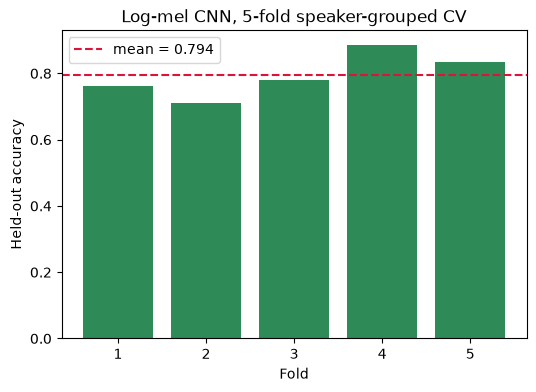

In [3]:
cv_results = pd.read_csv(f"{RESULTS_ROOT}/cv_cnn_logmel_intent.csv")
print(cv_results.to_string(index=False))
print(f"\nMean held-out accuracy: {cv_results['held_out_acc'].mean():.4f} +/- {cv_results['held_out_acc'].std():.4f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(cv_results["fold"], cv_results["held_out_acc"], color="seagreen")
ax.axhline(cv_results["held_out_acc"].mean(), color="crimson", linestyle="--",
           label=f"mean = {cv_results['held_out_acc'].mean():.3f}")
ax.set_xlabel("Fold"); ax.set_ylabel("Held-out accuracy"); ax.set_title("Log-mel CNN, 5-fold speaker-grouped CV")
ax.legend()
plt.show()

## Comparison with Notebook 08 (MFCC) and Notebook 09

The table and chart below place this stage's log-mel CNN alongside the two classical-feature CNNs it is directly comparable to: Notebook 08's single-head CNN on MFCC sequences (identical architecture, same CV protocol, only the front-end representation differs) and Notebook 09's multi-head CNN (a stronger architecture that predicts the action/object/location slots separately). All three are trained from scratch, with no pretrained model involved, consistent with this project's core constraint.

                   Model  Accuracy_pct  Std_pct
   1D-CNN, MFCC (13-dim)          72.5      5.0
1D-CNN, log-mel (40-dim)          79.4      6.8
 Multi-head 1D-CNN, MFCC          77.3      6.7


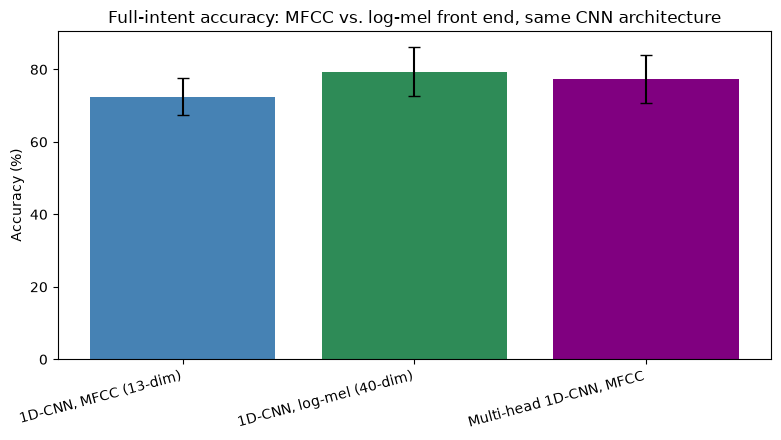

In [4]:
mfcc_cnn_cv = pd.read_csv(f"{RESULTS_ROOT}/cv_cnn_mfcc_intent.csv")
multihead_cv = pd.read_csv(f"{RESULTS_ROOT}/cv_cnn_multihead_mfcc.csv")

summary = pd.DataFrame([
    {"Model": "1D-CNN, MFCC (13-dim)", "Accuracy_pct": round(mfcc_cnn_cv["held_out_acc"].mean() * 100, 1),
     "Std_pct": round(mfcc_cnn_cv["held_out_acc"].std() * 100, 1)},
    {"Model": "1D-CNN, log-mel (40-dim)", "Accuracy_pct": round(cv_results["held_out_acc"].mean() * 100, 1),
     "Std_pct": round(cv_results["held_out_acc"].std() * 100, 1)},
    {"Model": "Multi-head 1D-CNN, MFCC", "Accuracy_pct": round(multihead_cv["full_intent_acc"].mean() * 100, 1),
     "Std_pct": round(multihead_cv["full_intent_acc"].std() * 100, 1)},
])
print(summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(summary["Model"], summary["Accuracy_pct"], yerr=summary["Std_pct"], capsize=4,
       color=["steelblue", "seagreen", "purple"])
ax.set_ylabel("Accuracy (%)")
ax.set_title("Full-intent accuracy: MFCC vs. log-mel front end, same CNN architecture")
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
fig.tight_layout()
plt.show()

## Results

The log-mel CNN reached **79.4% ± 6.8%** mean held-out accuracy across the 5 speaker-grouped folds (individual fold accuracies: 76.1%, 70.9%, 78.0%, 88.5%, 83.4%), compared to **72.5% ± 5.0%** for Notebook 08's identically-architected CNN on 13-dimensional MFCC sequences — a 6.9 percentage-point improvement from dropping the DCT step alone. It is also numerically above **77.3% ± 6.7%** for Notebook 09's multi-head CNN, a stronger architecture that predicts the action/object/location slots separately, despite Notebook 10 using the simpler single-head design.

This is a clean answer to the question this stage was built to test: the CNN did not need MFCC's cepstral decorrelation, and in fact performed *better* without it. The DCT is a fixed, information-preserving linear transform (invertible, given enough coefficients), so in principle a network could learn to undo its effect if decorrelation were actually helpful for classification; the fact that skipping it improved accuracy suggests the decorrelation was not merely neutral but mildly counterproductive for a convolutional architecture on this task.

Two caveats were noted at this point. The margin over Notebook 09's multi-head network (+2.1 points on average) is not consistent across folds (4 of 5 folds, paired $t$-test $p = 0.16$). In addition, the comparison changes two things at once relative to Notebook 08: the DCT is removed and the per-frame width grows from 13 to 40. The ablation below separates these two factors.

## DCT ablation: decorrelation versus truncation

MFCC differs from the log-mel input in two respects: an orthonormal DCT-II is applied across the mel bands, and only the first 13 coefficients are retained. To separate the two, the DCT was applied to the same 40-band log-mel frames used above, retaining either all 40 coefficients (an invertible transform that preserves every dimension) or only the first 13. Both variants were trained with the identical network, standardisation and speaker folds by `src/experiments/sequence_cv.py` (inputs `logmel_dct40` and `logmel_dct13`).

In [5]:
from scipy import stats

ablation = {
    "MFCC, 13 coefficients (128 mel bands)": pd.read_csv(f"{RESULTS_ROOT}/cv_cnn_mfcc_intent.csv"),
    "DCT of log-mel, first 13 coefficients": pd.read_csv(f"{RESULTS_ROOT}/cv_cnn_logmel_dct13_intent.csv"),
    "DCT of log-mel, all 40 coefficients": pd.read_csv(f"{RESULTS_ROOT}/cv_cnn_logmel_dct40_intent.csv"),
    "Log-mel, 40 bands": pd.read_csv(f"{RESULTS_ROOT}/cv_cnn_logmel_intent.csv"),
}
acc = {k: v.sort_values("fold")["held_out_acc"].values for k, v in ablation.items()}
table = pd.DataFrame({k: {"mean (%)": 100 * a.mean(), "std (%)": 100 * a.std(ddof=1),
                          **{f"fold {i+1}": 100 * x for i, x in enumerate(a)}} for k, a in acc.items()}).T
print(table.round(1).to_string())

def paired(a, b):
    d = 100 * (acc[a] - acc[b])
    return f"{d.mean():+.1f} points, higher in {(d > 0).sum()}/5 folds, paired t-test p = {stats.ttest_rel(acc[a], acc[b]).pvalue:.4f}"

print("\nLog-mel vs. DCT-40:   ", paired("Log-mel, 40 bands", "DCT of log-mel, all 40 coefficients"))
print("DCT-13 vs. DCT-40:    ", paired("DCT of log-mel, first 13 coefficients", "DCT of log-mel, all 40 coefficients"))
print("Log-mel vs. DCT-13:   ", paired("Log-mel, 40 bands", "DCT of log-mel, first 13 coefficients"))
print("DCT-13 vs. MFCC-13:   ", paired("DCT of log-mel, first 13 coefficients", "MFCC, 13 coefficients (128 mel bands)"))

                                       mean (%)  std (%)  fold 1  fold 2  fold 3  fold 4  fold 5
MFCC, 13 coefficients (128 mel bands)      72.5      5.0    69.8    65.4    72.9    76.7    77.6
DCT of log-mel, first 13 coefficients      73.1      5.8    68.8    66.4    73.9    81.3    75.3
DCT of log-mel, all 40 coefficients        63.5      5.0    61.1    58.8    61.9    71.9    64.0
Log-mel, 40 bands                          79.4      6.8    76.1    70.9    78.0    88.5    83.4

Log-mel vs. DCT-40:    +15.9 points, higher in 5/5 folds, paired t-test p = 0.0002
DCT-13 vs. DCT-40:     +9.6 points, higher in 5/5 folds, paired t-test p = 0.0004
Log-mel vs. DCT-13:    +6.3 points, higher in 5/5 folds, paired t-test p = 0.0014
DCT-13 vs. MFCC-13:    +0.7 points, higher in 3/5 folds, paired t-test p = 0.5986


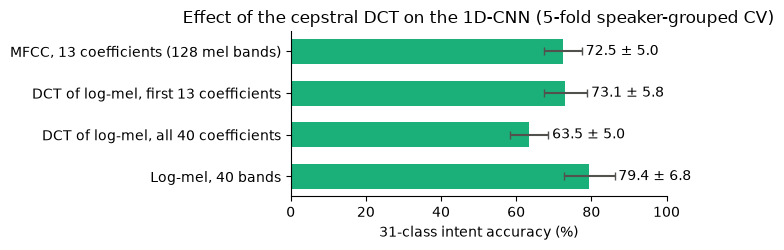

In [6]:
fig, ax = plt.subplots(figsize=(7, 2.6))
names = list(acc)[::-1]
means = [100 * acc[n].mean() for n in names]; sds = [100 * acc[n].std(ddof=1) for n in names]
ax.barh(names, means, xerr=sds, color="#1baf7a", height=0.6, error_kw=dict(ecolor="#52514e", capsize=3))
for y, (m, s) in enumerate(zip(means, sds)):
    ax.text(m + s + 1, y, f"{m:.1f} ± {s:.1f}", va="center")
ax.set_xlim(0, 100); ax.set_xlabel("31-class intent accuracy (%)")
ax.set_title("Effect of the cepstral DCT on the 1D-CNN (5-fold speaker-grouped CV)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## Variance of the inputs after standardisation

Every input channel is standardised to unit variance before training. The spread of the per-channel standard deviations before standardisation therefore indicates how strongly standardisation re-weights the channels.

In [7]:
from scipy.fft import dct

sample = np.asarray(X[:3000]).reshape(-1, X.shape[-1])
sample = sample[np.abs(sample).sum(axis=1) > 0]                 # drop zero-padded frames
logmel_sd = sample.std(axis=0)
dct_sd = dct(sample, type=2, norm="ortho", axis=-1).std(axis=0)

print(f"Log-mel bands:    std ranges {logmel_sd.min():.1f}-{logmel_sd.max():.1f} (ratio {logmel_sd.max()/logmel_sd.min():.1f})")
print(f"DCT coefficients: std ranges {dct_sd.min():.2f}-{dct_sd.max():.1f} (ratio {dct_sd.max()/dct_sd.min():.1f})")
print(f"Share of total variance in DCT coefficients 14-40: {(dct_sd[13:]**2).sum() / (dct_sd**2).sum():.3f}")

Log-mel bands:    std ranges 13.5-26.2 (ratio 1.9)
DCT coefficients: std ranges 1.83-110.5 (ratio 60.4)
Share of total variance in DCT coefficients 14-40: 0.022


## Results: DCT ablation

Retaining all 40 DCT coefficients lowered accuracy to **63.5% ± 5.0%**, 15.9 points below the log-mel input in every fold (p < 0.001), although this representation has the same dimensionality and is exactly invertible. Truncating the same transform to 13 coefficients recovered **73.1% ± 5.8%**, which is statistically indistinguishable from the original 13 MFCCs computed from 128 mel bands (p = 0.60). The advantage of the log-mel input is therefore due to the absence of the DCT, not to its additional dimensions, and the size of the mel filterbank has no measurable effect.

The variance analysis indicates the mechanism. The standard deviations of the 40 log-mel bands differ by a factor of about 2, whereas those of the 40 DCT coefficients differ by a factor of about 60, and coefficients 14-40 carry only about 2% of the total variance. Per-channel standardisation therefore gives these low-variance, high-quefrency coefficients, which mainly describe fine spectral detail and noise, the same weight as the coefficients that describe the spectral envelope. Truncation removes most of them, which is why 13 coefficients outperform 40. The DCT remains appropriate for diagonal-covariance Gaussian models, but for this convolutional classifier the log-mel representation is preferable.